# Physics-based network losses and transmission investment

This Draft 2 notebook extends the fixed-network market-clearing model with flow-dependent electrical losses and two types of investment: constructing a new link or upgrading the conductor on an existing link.

For each edge, the baseline conductor resistance is computed from `R = ρL/A`, where `A = πr²`. Under the selected balanced three-phase convention, sent power is `P = √3 V_line I PF`, and conductor loss is `P_loss = 3 I²R`. Thus received power is sent power minus the modeled resistive loss. All physics values and distance-based costs are explicitly editable, illustrative inputs, not validated engineering data.

The nonlinear quadratic loss curve is represented with a piecewise-linear approximation inside a mixed-integer market-clearing model. The greedy outer search compares affordable new-link builds and one-step conductor-area upgrades by their incremental welfare gain.

This is still a simplified transport model; it does not represent AC power-flow laws, reactive power, voltage variation, temperature-dependent resistance, parallel circuits, or real route geometry.

## 1. Imports and user configuration

Change `PERIOD_INDEX` to select one of the 96 quarter-hours. Run this notebook from the repository root so `./data` is found.

The starting transfer capacities and all conductor/electrical parameters below are illustrative. The baseline values are attached as columns to each edge so that individual links can be edited. New links inherit the listed global defaults.

In [1]:
from pathlib import Path
import json
import math

import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

# Run from the repository root; the market data are in ./data.
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
PERIOD_INDEX = 0
PLOT_MARKET = "AT"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        "Could not find ./data. Start Jupyter in the repository root, "
        "or set PROJECT_DIR above to that folder."
    )

print(f"Project directory: {PROJECT_DIR}")
print(f"Gurobi version: {gp.gurobi.version()}")

Project directory: /Users/gsims/Documents/GitHub/d2a_project/D2A_Project_Draft_2
Gurobi version: (12, 0, 3)


## 2. Load and validate the market files

In [2]:
def load_market_files(data_dir):
    """Load one JSON-formatted .txt file per aggregate bidding area."""
    markets = {}
    source_paths = {}

    for path in sorted(Path(data_dir).glob("*.txt")):
        with path.open("r", encoding="utf-8") as handle:
            payload = json.load(handle)

        area = payload.get("aggregatedBiddingArea")
        periods = payload.get("aggregatedPoints", [])
        if not area or not periods:
            raise ValueError(f"{path.name} is missing its area code or delivery periods")
        if area in markets:
            raise ValueError(f"Duplicate aggregate bidding area: {area}")

        markets[area] = payload
        source_paths[area] = path

    if not markets:
        raise FileNotFoundError(f"No .txt market files found in {data_dir}")

    period_counts = {area: len(payload["aggregatedPoints"]) for area, payload in markets.items()}
    if len(set(period_counts.values())) != 1:
        raise ValueError(f"Market files have inconsistent period counts: {period_counts}")

    return markets, source_paths


markets, source_paths = load_market_files(DATA_DIR)

market_overview = pd.DataFrame(
    [
        {
            "market": area,
            "periods": len(payload["aggregatedPoints"]),
            "delivery_date": payload.get("deliveryDate"),
            "file": source_paths[area].name,
        }
        for area, payload in sorted(markets.items())
    ]
)

print(f"Loaded {len(markets)} markets.")
display(market_overview)

Loaded 13 markets.


,market,periods,delivery_date,file
0,AT,96,2026-09-08,at.txt
1,BALTIC,96,2026-09-08,baltic.txt
2,BE,96,2026-09-08,be.txt
3,BG,96,2026-09-08,bg.txt
4,DE-LU,96,2026-09-08,de_lu.txt
5,DK,96,2026-09-08,dk.txt
6,FI,96,2026-09-08,fi.txt
7,FR,96,2026-09-08,fr.txt
8,NL,96,2026-09-08,nl.txt
9,NO,96,2026-09-08,no.txt


## 3. Convert cumulative schedules into incremental blocks

The raw curves are cumulative. Whenever cumulative quantity rises, the increase becomes one bounded bid block. A vertical price move with no quantity change creates no block. Adjacent blocks at the same price are merged.

The first cumulative quantity is treated as a block measured from zero. This preserves the absolute submitted supply and demand schedules rather than re-centering each market around its observed clearing point.

In [3]:
def cumulative_curve_to_blocks(series_data, side, quantity_tolerance=1e-7, price_tolerance=1e-10):
    """Convert one cumulative supply or demand schedule to (price, quantity) blocks."""
    if side not in {"supply", "demand"}:
        raise ValueError("side must be 'supply' or 'demand'")

    price_key = f"{side}Price"
    quantity_key = f"{side}Quantity"
    points = [
        (float(row[price_key]), float(row[quantity_key]))
        for row in series_data
        if price_key in row and quantity_key in row
    ]
    if not points:
        raise ValueError(f"No complete {side} price-quantity points found")

    blocks = []
    previous_quantity = 0.0
    for price, cumulative_quantity in points:
        if not (math.isfinite(price) and math.isfinite(cumulative_quantity)):
            raise ValueError(f"Non-finite {side} point: {(price, cumulative_quantity)}")
        if cumulative_quantity < previous_quantity - quantity_tolerance:
            raise ValueError(
                f"{side.title()} cumulative quantity fell from "
                f"{previous_quantity} to {cumulative_quantity}"
            )

        block_quantity = cumulative_quantity - previous_quantity
        if block_quantity > quantity_tolerance:
            if blocks and abs(blocks[-1]["price"] - price) <= price_tolerance:
                blocks[-1]["quantity"] += block_quantity
            else:
                blocks.append({"price": price, "quantity": block_quantity})
        previous_quantity = max(previous_quantity, cumulative_quantity)

    result = pd.DataFrame(blocks)
    result.insert(0, "block_id", np.arange(len(result), dtype=int))
    result["side"] = side
    return result[["block_id", "side", "price", "quantity"]]


def published_price_summary(period):
    """Return published component prices and their mean for an aggregate file."""
    records = period.get("priceAreas", [])
    prices = {
        str(record["area"]): float(record["price"])
        for record in records
        if "area" in record and "price" in record
    }
    mean_price = float(np.mean(list(prices.values()))) if prices else np.nan
    return prices, mean_price


def prepare_period(markets, period_index):
    """Parse the selected period for every market into optimizer-ready blocks."""
    prepared = {}
    delivery_starts = set()
    delivery_ends = set()

    for area, payload in sorted(markets.items()):
        periods = payload["aggregatedPoints"]
        if period_index < 0 or period_index >= len(periods):
            raise IndexError(f"PERIOD_INDEX={period_index} is invalid for {area}")

        period = periods[period_index]
        delivery_starts.add(period["deliveryStart"])
        delivery_ends.add(period["deliveryEnd"])
        prices, mean_price = published_price_summary(period)
        prepared[area] = {
            "supply": cumulative_curve_to_blocks(period["seriesData"], "supply"),
            "demand": cumulative_curve_to_blocks(period["seriesData"], "demand"),
            "published_prices": prices,
            "published_price_mean": mean_price,
            "delivery_start": period["deliveryStart"],
            "delivery_end": period["deliveryEnd"],
        }

    if len(delivery_starts) != 1 or len(delivery_ends) != 1:
        raise ValueError(
            "The selected period is not time-aligned across markets: "
            f"starts={delivery_starts}, ends={delivery_ends}"
        )

    return prepared


period_data = prepare_period(markets, PERIOD_INDEX)
delivery_start = next(iter(period_data.values()))["delivery_start"]
delivery_end = next(iter(period_data.values()))["delivery_end"]

block_summary = pd.DataFrame(
    [
        {
            "market": area,
            "supply_blocks": len(data["supply"]),
            "max_supply_mw": data["supply"]["quantity"].sum(),
            "demand_blocks": len(data["demand"]),
            "max_demand_mw": data["demand"]["quantity"].sum(),
            "published_price_mean": data["published_price_mean"],
        }
        for area, data in sorted(period_data.items())
    ]
)

print(f"Selected period {PERIOD_INDEX}: {delivery_start} to {delivery_end}")
display(block_summary)

Selected period 0: 2026-09-07T22:00:00Z to 2026-09-07T22:15:00Z


,market,supply_blocks,max_supply_mw,demand_blocks,max_demand_mw,published_price_mean
0,AT,26,"3,465.700",42,"3,571.400",224.970
1,BALTIC,225,"3,178.900",268,"2,582.700",5.000
2,BE,128,"4,512.900",135,"5,851.700",206.480
3,BG,92,"2,890.300",706,"2,919.300",224.550
4,DE-LU,353,"33,960.500",604,"40,817.300",205.990
5,DK,245,"4,794.400",178,"5,882.700",206.100
6,FI,289,"9,427.000",213,"8,972.900",2.030
7,FR,102,"19,334.100",83,"19,826.100",207.650
8,NL,381,"9,579.700",328,"11,940.200",206.000
9,NO,785,"18,993.500",175,"13,548.852",105.924


### Inspect one transformed market

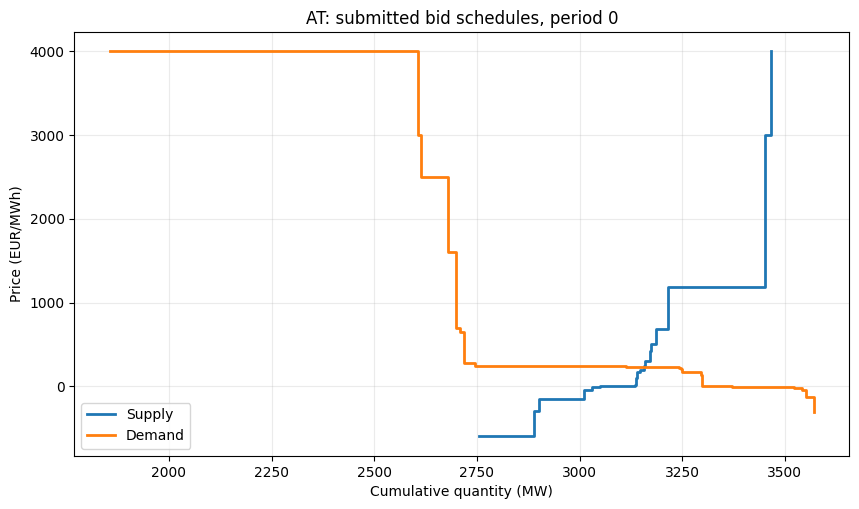

First 10 incremental supply blocks


,block_id,side,price,quantity,cumulative_quantity
0,0,supply,-600.000,"2,756.400","2,756.400"
1,1,supply,-599.900,29.500,"2,785.900"
2,2,supply,-301.000,103.296,"2,889.196"
3,3,supply,-300.000,8.204,"2,897.400"
4,4,supply,-150.000,5.000,"2,902.400"
5,5,supply,-131.600,109.000,"3,011.400"
6,6,supply,-50.000,0.500,"3,011.900"
7,7,supply,-5.000,18.100,"3,030.000"
8,8,supply,-1.000,20.100,"3,050.100"
9,9,supply,0.000,42.500,"3,092.600"


First 10 incremental demand blocks


,block_id,side,price,quantity,cumulative_quantity
0,0,demand,"4,000.000","1,855.800","1,855.800"
1,1,demand,"3,999.900",606.800,"2,462.600"
2,2,demand,"3,000.000",144.233,"2,606.833"
3,3,demand,"2,500.010",7.867,"2,614.700"
4,4,demand,"2,500.000",15.800,"2,630.500"
5,5,demand,"1,606.000",50.000,"2,680.500"
6,6,demand,699.990,19.600,"2,700.100"
7,7,demand,688.900,7.800,"2,707.900"
8,8,demand,650.000,0.300,"2,708.200"
9,9,demand,520.000,10.000,"2,718.200"


In [4]:
if PLOT_MARKET not in period_data:
    raise KeyError(f"PLOT_MARKET={PLOT_MARKET!r} is not one of {sorted(period_data)}")

supply_plot = period_data[PLOT_MARKET]["supply"].copy()
demand_plot = period_data[PLOT_MARKET]["demand"].copy()
supply_plot["cumulative_quantity"] = supply_plot["quantity"].cumsum()
demand_plot["cumulative_quantity"] = demand_plot["quantity"].cumsum()

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.step(
    supply_plot["cumulative_quantity"], supply_plot["price"],
    where="post", label="Supply", linewidth=2,
)
ax.step(
    demand_plot["cumulative_quantity"], demand_plot["price"],
    where="post", label="Demand", linewidth=2,
)
ax.set_title(f"{PLOT_MARKET}: submitted bid schedules, period {PERIOD_INDEX}")
ax.set_xlabel("Cumulative quantity (MW)")
ax.set_ylabel("Price (EUR/MWh)")
ax.grid(alpha=0.25)
ax.legend()
plt.show()

print("First 10 incremental supply blocks")
display(supply_plot.head(10))
print("First 10 incremental demand blocks")
display(demand_plot.head(10))

## 4. Define the starting transport network

Each row is one undirected commercial interconnector. The directional model prevents simultaneous counterflows. The listed `capacity_mw` is an independent baseline transfer cap; the usable flow is also limited by the three-phase ampacity implied by voltage, power factor, and maximum current. A conductor upgrade scales both the table cap and ampacity by its area multiplier.

The topology and table capacities are illustrative, not verified historical data. Conductor length uses the same straight-line market-coordinate approximation used for distance-based construction cost; actual route lengths and electrical parameters should replace these defaults before empirical or engineering interpretation.

In [5]:
BASE_INTERCONNECTORS = pd.DataFrame(
    [
        # Central-western Europe
        ("AT", "DE-LU", 4_000.0),
        ("BE", "DE-LU", 2_000.0),
        ("BE", "FR", 3_500.0),
        ("BE", "NL", 2_400.0),
        ("DE-LU", "FR", 4_000.0),
        ("DE-LU", "NL", 5_000.0),
        ("DE-LU", "PL", 2_500.0),
        # Nordic and continental links
        ("DE-LU", "DK", 2_500.0),
        ("DE-LU", "SE", 600.0),
        ("DK", "NL", 700.0),
        ("DK", "NO", 1_700.0),
        ("DK", "SE", 2_000.0),
        ("FI", "NO", 100.0),
        ("FI", "SE", 2_700.0),
        ("NO", "NL", 700.0),
        ("NO", "SE", 3_500.0),
        # Baltic and eastern links
        ("BALTIC", "FI", 1_000.0),
        ("BALTIC", "PL", 500.0),
        ("BALTIC", "SE", 700.0),
        ("PL", "SE", 600.0),
        ("BG", "RO", 1_500.0),
    ],
    columns=["from_market", "to_market", "capacity_mw"],
)

# A conservative demonstration scale that makes transfer scarcity visible.
# Set this to 1.0 to use the round base values exactly as listed above.
ILLUSTRATIVE_CAPACITY_SCALE = 0.5
INTERCONNECTORS = BASE_INTERCONNECTORS.copy()
INTERCONNECTORS["capacity_mw"] *= ILLUSTRATIVE_CAPACITY_SCALE


def validate_interconnectors(interconnectors, valid_markets):
    required = {"from_market", "to_market", "capacity_mw"}
    if not required.issubset(interconnectors.columns):
        raise ValueError(f"Interconnector table must contain {sorted(required)}")

    unknown = (
        set(interconnectors["from_market"])
        | set(interconnectors["to_market"])
    ) - set(valid_markets)
    if unknown:
        raise ValueError(f"Unknown markets in interconnector table: {sorted(unknown)}")
    if (interconnectors["from_market"] == interconnectors["to_market"]).any():
        raise ValueError("Self-links are not allowed")
    if (interconnectors["capacity_mw"] < 0).any():
        raise ValueError("Capacities must be nonnegative")

    normalized_pairs = interconnectors.apply(
        lambda row: tuple(sorted((row["from_market"], row["to_market"]))), axis=1
    )
    if normalized_pairs.duplicated().any():
        duplicates = normalized_pairs[normalized_pairs.duplicated(keep=False)].tolist()
        raise ValueError(f"Duplicate undirected links: {duplicates}")


validate_interconnectors(INTERCONNECTORS, period_data)
display(INTERCONNECTORS)

,from_market,to_market,capacity_mw
0,AT,DE-LU,"2,000.000"
1,BE,DE-LU,"1,000.000"
2,BE,FR,"1,750.000"
3,BE,NL,"1,200.000"
4,DE-LU,FR,"2,000.000"
5,DE-LU,NL,"2,500.000"
6,DE-LU,PL,"1,250.000"
7,DE-LU,DK,"1,250.000"
8,DE-LU,SE,300.000
9,DK,NL,350.000


In [6]:
# Representative market-centre coordinates (latitude, longitude in degrees).
MARKET_COORDINATES = {
    "AT": (48.2085, 16.3721),
    "BE": (50.8505, 4.3488),
    "BALTIC": (59.4370, 24.7540),
    "BG": (42.7333, 25.4858),
    "DE-LU": (52.5200, 13.4050),
    "DK": (55.6761, 12.5683),
    "FI": (60.1700, 24.9400),
    "FR": (48.8566, 2.3522),
    "NL": (52.3700, 4.8900),
    "NO": (59.9100, 10.7500),
    "PL": (52.2297, 21.0122),
    "RO": (44.4268, 26.1025),
    "SE": (59.3300, 18.0600),
}

# Illustrative defaults; replace with sourced, edge-specific engineering data.
RESISTIVITY_OHM_M = 2.82e-8  # aluminium at approximately 20 C
CONDUCTOR_RADIUS_M = 0.015
NOMINAL_LINE_VOLTAGE_V = 400_000.0
MAX_CURRENT_A = 2_000.0
POWER_FACTOR = 1.0
AREA_UPGRADE_MULTIPLIER = 2.0
# Investment costs are in million GBP. The notebook's new-line benchmark is £1.6m/km.
# Reference: https://www.nationalgrid.com/document/282876/download
NEW_LINE_COST_MILLION_GBP_PER_KM = 1.6
# The 2035 Report says advanced reconductoring can cost less than half of new-line
# construction; use a conservative 40% midpoint as an illustrative scenario assumption.
# Reference: https://www.2035report.com/reconductoring/
WIRE_UPGRADE_COST_FRACTION_OF_NEW_LINE = 0.40
WIRE_UPGRADE_COST_MILLION_GBP_PER_KM = (
    WIRE_UPGRADE_COST_FRACTION_OF_NEW_LINE * NEW_LINE_COST_MILLION_GBP_PER_KM
)
LOSS_PIECEWISE_SEGMENTS = 8

# Investment cost and budget values below are in million GBP; welfare remains EUR.
CANDIDATE_EDGE_CAPACITY_MW = float(INTERCONNECTORS["capacity_mw"].median())
BUDGET_MULTIPLIER = 10.0
MAX_GREEDY_ITERATIONS = 50
MIN_SURPLUS_GAIN = 0.50


def distance_km(market_a, market_b):
    """Return the repository's straight-line latitude/longitude approximation in km."""
    lat1, lon1 = MARKET_COORDINATES[market_a]
    lat2, lon2 = MARKET_COORDINATES[market_b]
    lat1, lon1, lat2, lon2 = map(math.radians, (lat1, lon1, lat2, lon2))
    delta_phi = lat2 - lat1
    delta_lam = lon2 - lon1
    mean_phi = (lat2 + lat1) / 2.0
    return 6371.0 * math.sqrt(delta_phi**2 + (math.cos(mean_phi) * delta_lam) ** 2)


def edge_creation_cost(market_a, market_b):
    """Match Constants.cost_to_create(): int(1.6 * straight_line_distance_km)."""
    return int(NEW_LINE_COST_MILLION_GBP_PER_KM * distance_km(market_a, market_b))


def add_physics_parameters(interconnectors):
    """Attach illustrative baseline conductor data to each interconnector row."""
    result = interconnectors.copy().reset_index(drop=True)
    if "base_capacity_mw" not in result:
        result["base_capacity_mw"] = result["capacity_mw"].astype(float)
    result["area_multiplier"] = 1.0
    result["length_km"] = [
        distance_km(row.from_market, row.to_market)
        for row in result.itertuples(index=False)
    ]
    result["resistivity_ohm_m"] = RESISTIVITY_OHM_M
    result["base_radius_m"] = CONDUCTOR_RADIUS_M
    result["voltage_line_v"] = NOMINAL_LINE_VOLTAGE_V
    result["base_max_current_a"] = MAX_CURRENT_A
    result["power_factor"] = POWER_FACTOR
    result["creation_cost"] = [
        edge_creation_cost(row.from_market, row.to_market)
        for row in result.itertuples(index=False)
    ]
    result["upgrade_cost_million_gbp"] = (
        WIRE_UPGRADE_COST_MILLION_GBP_PER_KM * result["length_km"]
    )
    return result


INTERCONNECTORS = add_physics_parameters(INTERCONNECTORS)
print(f"Physics assumptions: ρ={RESISTIVITY_OHM_M:.3g} Ω·m, r={CONDUCTOR_RADIUS_M:.3f} m, "
      f"V={NOMINAL_LINE_VOLTAGE_V/1000:.0f} kV, Imax={MAX_CURRENT_A:.0f} A, PF={POWER_FACTOR:.2f}")
print(f"One conductor upgrade multiplies area and baseline transfer/thermal capacity by {AREA_UPGRADE_MULTIPLIER:.2f}×.")
print(f"Upgrade cost assumption: {WIRE_UPGRADE_COST_MILLION_GBP_PER_KM:.3f} million GBP/km.")
display(INTERCONNECTORS)

Physics assumptions: ρ=2.82e-08 Ω·m, r=0.015 m, V=400 kV, Imax=2000 A, PF=1.00
One conductor upgrade multiplies area and baseline transfer/thermal capacity by 2.00×.
Upgrade cost assumption: 0.640 million GBP/km.


,from_market,to_market,capacity_mw,base_capacity_mw,area_multiplier,length_km,resistivity_ohm_m,base_radius_m,voltage_line_v,base_max_current_a,power_factor,creation_cost,upgrade_cost_million_gbp
0,AT,DE-LU,"2,000.000","2,000.000",1.000,523.579,0.000,0.015,"400,000.000","2,000.000",1.000,837,335.090
1,BE,DE-LU,"1,000.000","1,000.000",1.000,651.338,0.000,0.015,"400,000.000","2,000.000",1.000,1042,416.856
2,BE,FR,"1,750.000","1,750.000",1.000,263.904,0.000,0.015,"400,000.000","2,000.000",1.000,422,168.898
3,BE,NL,"1,200.000","1,200.000",1.000,173.044,0.000,0.015,"400,000.000","2,000.000",1.000,276,110.748
4,DE-LU,FR,"2,000.000","2,000.000",1.000,878.748,0.000,0.015,"400,000.000","2,000.000",1.000,1405,562.399
5,DE-LU,NL,"2,500.000","2,500.000",1.000,577.352,0.000,0.015,"400,000.000","2,000.000",1.000,923,369.505
6,DE-LU,PL,"1,250.000","1,250.000",1.000,517.413,0.000,0.015,"400,000.000","2,000.000",1.000,827,331.144
7,DE-LU,DK,"1,250.000","1,250.000",1.000,355.158,0.000,0.015,"400,000.000","2,000.000",1.000,568,227.301
8,DE-LU,SE,300.000,300.000,1.000,810.871,0.000,0.015,"400,000.000","2,000.000",1.000,1297,518.958
9,DK,NL,350.000,350.000,1.000,621.863,0.000,0.015,"400,000.000","2,000.000",1.000,994,397.993


## 5. Build and solve the physics-based market-clearing model

For each directional flow, the sent MW is converted to current using `I = P/(√3 V_line PF)`. Resistance follows `R = ρL/(πr² × area_multiplier)`, and three-phase power loss is `3I²R`. The convex quadratic loss relation is approximated by `LOSS_PIECEWISE_SEGMENTS` piecewise-linear segments. The maximum transfer is the smaller of the link's current transfer cap and its voltage/ampacity rating.

The direction binaries make clearing a mixed-integer model. Conditional on the selected directions, a second continuous piecewise-linear solve provides nodal-price and marginal-capacity diagnostics.

In [7]:
def edge_electrical_properties(edge):
    """Compute conductor resistance and maximum sending power for one edge."""
    area_m2 = math.pi * float(edge["base_radius_m"]) ** 2 * float(edge["area_multiplier"])
    resistance_ohm = float(edge["resistivity_ohm_m"]) * float(edge["length_km"]) * 1000.0 / area_m2
    current_limit_a = float(edge["base_max_current_a"]) * float(edge["area_multiplier"])
    voltage_v = float(edge["voltage_line_v"])
    power_factor = float(edge["power_factor"])
    if resistance_ohm <= 0 or voltage_v <= 0 or current_limit_a <= 0 or not 0 < power_factor <= 1:
        raise ValueError(f"Invalid electrical parameters for {edge['from_market']}--{edge['to_market']}")
    thermal_limit_mw = math.sqrt(3.0) * voltage_v * current_limit_a * power_factor / 1e6
    flow_limit_mw = min(float(edge["capacity_mw"]), thermal_limit_mw)
    if flow_limit_mw <= 0:
        raise ValueError(f"Nonpositive transfer limit for {edge['from_market']}--{edge['to_market']}")
    return resistance_ohm, current_limit_a, thermal_limit_mw, flow_limit_mw


def resistive_loss_mw(sent_mw, resistance_ohm, voltage_line_v, power_factor):
    """Balanced three-phase copper loss 3 I^2 R, in MW."""
    current_a = float(sent_mw) * 1e6 / (
        math.sqrt(3.0) * float(voltage_line_v) * float(power_factor)
    )
    return 3.0 * current_a**2 * float(resistance_ohm) / 1e6


def solve_market(period_data, interconnectors, model_name="market_clearing", output_flag=0, diagnostics=True):
    """Solve clearing with PWL resistive losses; optionally estimate local LP prices."""
    nodes = sorted(period_data)
    edges = interconnectors.reset_index(drop=True).copy()
    validate_interconnectors(edges, nodes)
    required = {
        "area_multiplier", "length_km", "resistivity_ohm_m", "base_radius_m",
        "voltage_line_v", "base_max_current_a", "power_factor",
    }
    if not edges.empty and not required.issubset(edges.columns):
        raise ValueError(f"Edges lack physics columns: {sorted(required - set(edges.columns))}")

    def build_and_solve(fixed_directions=None, reference_flows=None, suffix=""):
        model = gp.Model(model_name + suffix)
        model.Params.OutputFlag = output_flag
        model.Params.Method = 1
        supply_vars, demand_vars = {}, {}
        forward_vars, reverse_vars = {}, {}
        forward_losses, reverse_losses = {}, {}
        direction_vars, edge_data = {}, {}

        for node in nodes:
            for block in period_data[node]["supply"].itertuples(index=False):
                supply_vars[(node, block.block_id)] = model.addVar(
                    lb=0.0, ub=float(block.quantity), obj=-float(block.price),
                    name=f"supply[{node},{block.block_id}]",
                )
            for block in period_data[node]["demand"].itertuples(index=False):
                demand_vars[(node, block.block_id)] = model.addVar(
                    lb=0.0, ub=float(block.quantity), obj=float(block.price),
                    name=f"demand[{node},{block.block_id}]",
                )

        for edge_id, edge in edges.iterrows():
            resistance, current_limit, thermal_limit, flow_limit = edge_electrical_properties(edge)
            breakpoints = np.linspace(0.0, flow_limit, LOSS_PIECEWISE_SEGMENTS + 1)
            loss_points = [
                resistive_loss_mw(point, resistance, edge["voltage_line_v"], edge["power_factor"])
                for point in breakpoints
            ]
            edge_data[edge_id] = {
                "resistance_ohm": resistance,
                "current_limit_a": current_limit,
                "thermal_limit_mw": thermal_limit,
                "flow_limit_mw": flow_limit,
                "breakpoints": breakpoints,
                "loss_points": loss_points,
            }
            fixed = None if fixed_directions is None else fixed_directions[edge_id]
            reference_forward, reference_reverse = (0.0, 0.0)
            if reference_flows is not None:
                reference_forward, reference_reverse = reference_flows[edge_id]

            def flow_bounds(active_direction, reference_flow):
                if fixed_directions is None:
                    return 0.0, flow_limit
                if fixed != active_direction:
                    return 0.0, 0.0
                segment = int(np.searchsorted(breakpoints, reference_flow, side="right") - 1)
                segment = min(max(segment, 0), len(breakpoints) - 2)
                return float(breakpoints[segment]), float(breakpoints[segment + 1])

            f_lb, f_ub = flow_bounds("forward", reference_forward)
            r_lb, r_ub = flow_bounds("reverse", reference_reverse)
            forward_vars[edge_id] = model.addVar(lb=f_lb, ub=f_ub, name=f"flow_forward[{edge_id}]")
            reverse_vars[edge_id] = model.addVar(lb=r_lb, ub=r_ub, name=f"flow_reverse[{edge_id}]")
            forward_losses[edge_id] = model.addVar(lb=0.0, ub=loss_points[-1], name=f"loss_forward[{edge_id}]")
            reverse_losses[edge_id] = model.addVar(lb=0.0, ub=loss_points[-1], name=f"loss_reverse[{edge_id}]")

            if fixed_directions is None:
                direction = model.addVar(vtype=GRB.BINARY, name=f"direction[{edge_id}]")
                direction_vars[edge_id] = direction
                model.addConstr(forward_vars[edge_id] <= flow_limit * direction)
                model.addConstr(reverse_vars[edge_id] <= flow_limit * (1 - direction))
                model.addGenConstrPWL(
                    forward_vars[edge_id], forward_losses[edge_id], breakpoints.tolist(), loss_points,
                    name=f"pwl_loss_forward[{edge_id}]",
                )
                model.addGenConstrPWL(
                    reverse_vars[edge_id], reverse_losses[edge_id], breakpoints.tolist(), loss_points,
                    name=f"pwl_loss_reverse[{edge_id}]",
                )
            else:
                for direction, flow_var, loss_var, reference_flow in (
                    ("forward", forward_vars[edge_id], forward_losses[edge_id], reference_forward),
                    ("reverse", reverse_vars[edge_id], reverse_losses[edge_id], reference_reverse),
                ):
                    if fixed == direction:
                        segment = int(np.searchsorted(breakpoints, reference_flow, side="right") - 1)
                        segment = min(max(segment, 0), len(breakpoints) - 2)
                        x0, x1 = breakpoints[segment], breakpoints[segment + 1]
                        y0, y1 = loss_points[segment], loss_points[segment + 1]
                        slope = (y1 - y0) / (x1 - x0)
                        model.addConstr(loss_var == y0 + slope * (flow_var - x0))
                    else:
                        model.addConstr(loss_var == 0.0)

        balance_constraints = {}
        for node in nodes:
            expression = gp.quicksum(
                supply_vars[(node, block_id)]
                for block_id in period_data[node]["supply"]["block_id"]
            ) - gp.quicksum(
                demand_vars[(node, block_id)]
                for block_id in period_data[node]["demand"]["block_id"]
            )
            for edge_id, edge in edges.iterrows():
                if node == edge["from_market"]:
                    expression += -forward_vars[edge_id] + reverse_vars[edge_id] - reverse_losses[edge_id]
                elif node == edge["to_market"]:
                    expression += forward_vars[edge_id] - forward_losses[edge_id] - reverse_vars[edge_id]
            balance_constraints[node] = model.addConstr(expression == 0.0, name=f"balance[{node}]")

        model.ModelSense = GRB.MAXIMIZE
        model.optimize()
        if model.Status != GRB.OPTIMAL:
            raise RuntimeError(f"Gurobi did not find an optimum; status={model.Status}")
        return (model, supply_vars, demand_vars, forward_vars, reverse_vars,
                forward_losses, reverse_losses, direction_vars, balance_constraints, edge_data)

    primary = build_and_solve()
    (model, supply_vars, demand_vars, forward_vars, reverse_vars,
     forward_losses, reverse_losses, direction_vars, balance_constraints, edge_data) = primary

    if diagnostics:
        chosen_directions = {
            edge_id: ("forward" if variable.X > 0.5 else "reverse")
            for edge_id, variable in direction_vars.items()
        }
        reference_flows = {
            edge_id: (forward_vars[edge_id].X, reverse_vars[edge_id].X)
            for edge_id in edges.index
        }
        price_result = build_and_solve(
            chosen_directions, reference_flows, "_local_segment_prices"
        )
        (price_model, price_supply, price_demand, price_forward, price_reverse,
         price_forward_losses, price_reverse_losses, _, price_balances, price_edge_data) = price_result
        if not np.isclose(model.ObjVal, price_model.ObjVal, rtol=1e-8, atol=1e-4):
            raise AssertionError("Local-segment pricing LP disagrees with PWL MILP welfare")
        result_model, result_supply, result_demand = price_model, price_supply, price_demand
        result_forward, result_reverse = price_forward, price_reverse
        result_forward_losses, result_reverse_losses = price_forward_losses, price_reverse_losses
        result_balances, result_edge_data = price_balances, price_edge_data
    else:
        result_model, result_supply, result_demand = model, supply_vars, demand_vars
        result_forward, result_reverse = forward_vars, reverse_vars
        result_forward_losses, result_reverse_losses = forward_losses, reverse_losses
        result_balances, result_edge_data = {}, edge_data

    node_rows = []
    supply_cost_total = demand_benefit_total = 0.0
    for node in nodes:
        supply_blocks = period_data[node]["supply"].set_index("block_id")
        demand_blocks = period_data[node]["demand"].set_index("block_id")
        supply_amount = sum(v.X for (area, _), v in result_supply.items() if area == node)
        demand_amount = sum(v.X for (area, _), v in result_demand.items() if area == node)
        supply_cost = sum(
            float(supply_blocks.loc[block_id, "price"]) * variable.X
            for (area, block_id), variable in result_supply.items() if area == node
        )
        demand_benefit = sum(
            float(demand_blocks.loc[block_id, "price"]) * variable.X
            for (area, block_id), variable in result_demand.items() if area == node
        )
        supply_cost_total += supply_cost
        demand_benefit_total += demand_benefit
        price = -float(result_balances[node].Pi) if diagnostics else np.nan
        residual = float(result_balances[node].Slack) if diagnostics else np.nan
        node_rows.append({
            "market": node,
            "supply_mw": supply_amount,
            "demand_mw": demand_amount,
            "net_export_mw": supply_amount - demand_amount,
            "nodal_price_eur_per_mwh": price,
            "published_price_mean": period_data[node]["published_price_mean"],
            "price_error": price - period_data[node]["published_price_mean"],
            "gross_benefit_eur_per_h": demand_benefit,
            "supply_cost_eur_per_h": supply_cost,
            "balance_residual_mw": residual,
        })
    node_results = pd.DataFrame(node_rows).sort_values("market").reset_index(drop=True)
    prices = node_results.set_index("market")["nodal_price_eur_per_mwh"].to_dict()

    flow_rows = []
    for edge_id, edge in edges.iterrows():
        f_flow = float(result_forward[edge_id].X)
        r_flow = float(result_reverse[edge_id].X)
        f_loss = float(result_forward_losses[edge_id].X)
        r_loss = float(result_reverse_losses[edge_id].X)
        flow = max(f_flow, r_flow)
        loss = f_loss if f_flow >= r_flow else r_loss
        details = result_edge_data[edge_id]
        current = flow * 1e6 / (
            math.sqrt(3.0) * float(edge["voltage_line_v"]) * float(edge["power_factor"])
        )
        source, destination = (
            (edge["from_market"], edge["to_market"])
            if f_flow >= r_flow else (edge["to_market"], edge["from_market"])
        )
        active_variable = result_forward[edge_id] if f_flow >= r_flow else result_reverse[edge_id]
        flow_limit = details["flow_limit_mw"]
        at_limit = flow >= flow_limit - max(1e-5, 1e-6 * flow_limit)
        marginal_value = abs(float(active_variable.RC)) if diagnostics and at_limit else 0.0
        price_gap = prices[destination] - prices[source] if diagnostics else np.nan
        flow_rows.append({
            "configured_link": f"{edge['from_market']} -- {edge['to_market']}",
            "actual_direction": f"{source} -> {destination}",
            "signed_flow_mw": f_flow - r_flow,
            "flow_mw": flow,
            "received_mw": flow - loss,
            "loss_mw": loss,
            "loss_fraction": loss / flow if flow > 1e-9 else 0.0,
            "current_a": current,
            "resistance_ohm": details["resistance_ohm"],
            "length_km": float(edge["length_km"]),
            "thermal_limit_mw": details["thermal_limit_mw"],
            "flow_limit_mw": flow_limit,
            "capacity_mw": float(edge["capacity_mw"]),
            "utilization": flow / flow_limit,
            "at_limit": at_limit,
            "economically_binding": at_limit and marginal_value > 1e-6,
            "receiving_minus_sending_price": price_gap,
            "marginal_value_of_more_capacity": marginal_value,
            "congestion_rent_eur_per_h": flow * abs(price_gap) if diagnostics else np.nan,
        })
    flow_results = pd.DataFrame(flow_rows)
    if not flow_results.empty:
        flow_results = flow_results.sort_values(
            ["economically_binding", "at_limit", "utilization"],
            ascending=[False, False, False],
        ).reset_index(drop=True)

    welfare = float(model.ObjVal)
    objective_check = demand_benefit_total - supply_cost_total
    if not np.isclose(welfare, objective_check, rtol=1e-8, atol=1e-4):
        raise AssertionError(f"Objective mismatch: model={welfare}, reconstructed={objective_check}")
    if diagnostics:
        model.dispose()
    return {
        "model": result_model,
        "nodes": node_results,
        "flows": flow_results,
        "welfare": welfare,
        "gross_benefit": demand_benefit_total,
        "supply_cost": supply_cost_total,
        "delivery_start": next(iter(period_data.values()))["delivery_start"],
        "delivery_end": next(iter(period_data.values()))["delivery_end"],
    }

## 6. Compare autarky and constrained trade

Autarky uses the same bid blocks but no inter-area links. Network welfare accounts for flow-dependent resistive losses on every transfer. Therefore, the welfare difference isolates the value of trade permitted by the configured transport network for this one 15-minute market-clearing interval.

The objective is reported in EUR/hour because prices are EUR/MWh and quantities are MW. Multiply the objective or welfare gain by `0.25` to obtain EUR for a 15-minute interval.

In [8]:
AUTARKY_LINKS = pd.DataFrame(
    columns=["from_market", "to_market", "capacity_mw"]
)

autarky = solve_market(period_data, AUTARKY_LINKS, model_name="autarky")
network = solve_market(period_data, INTERCONNECTORS, model_name="constrained_network")

scenario_summary = pd.DataFrame(
    [
        {
            "scenario": "Autarky",
            "welfare_eur_per_h": autarky["welfare"],
            "welfare_for_15min_eur": 0.25 * autarky["welfare"],
            "gain_vs_autarky_eur_per_h": 0.0,
            "gain_vs_autarky_for_15min_eur": 0.0,
        },
        {
            "scenario": "Capacity-constrained network",
            "welfare_eur_per_h": network["welfare"],
            "welfare_for_15min_eur": 0.25 * network["welfare"],
            "gain_vs_autarky_eur_per_h": network["welfare"] - autarky["welfare"],
            "gain_vs_autarky_for_15min_eur": 0.25 * (network["welfare"] - autarky["welfare"]),
        },
    ]
)

display(scenario_summary)

Set parameter Username
Set parameter LicenseID to value 2858384
Academic license - for non-commercial use only - expires 2027-08-28


,scenario,welfare_eur_per_h,welfare_for_15min_eur,gain_vs_autarky_eur_per_h,gain_vs_autarky_for_15min_eur
0,Autarky,"456,050,765.054","114,012,691.263",0.000,0.000
1,Capacity-constrained network,"456,514,177.095","114,128,544.274","463,412.042","115,853.010"


### Nodal quantities and prices

In [9]:
node_comparison = (
    autarky["nodes"][[
        "market", "supply_mw", "demand_mw", "nodal_price_eur_per_mwh"
    ]]
    .rename(
        columns={
            "supply_mw": "autarky_supply_mw",
            "demand_mw": "autarky_demand_mw",
            "nodal_price_eur_per_mwh": "autarky_price",
        }
    )
    .merge(
        network["nodes"][[
            "market", "supply_mw", "demand_mw", "net_export_mw",
            "nodal_price_eur_per_mwh", "published_price_mean", "price_error"
        ]],
        on="market",
        how="inner",
    )
    .rename(
        columns={
            "supply_mw": "network_supply_mw",
            "demand_mw": "network_demand_mw",
            "nodal_price_eur_per_mwh": "network_price",
        }
    )
)

display(node_comparison)

,market,autarky_supply_mw,autarky_demand_mw,autarky_price,network_supply_mw,network_demand_mw,net_export_mw,network_price,published_price_mean,price_error
0,AT,"3,146.800","3,146.800",224.900,"3,137.800","3,250.400",-112.600,166.761,224.970,-58.209
1,BALTIC,"2,376.157","2,376.157",5.010,"2,585.900","2,346.296",239.604,21.060,5.000,16.060
2,BE,"4,405.500","4,405.500",208.000,"4,248.000","4,452.400",-204.400,172.532,206.480,-33.948
3,BG,"2,806.800","2,806.800",210.000,"2,806.800","2,806.800",0.000,221.110,224.550,-3.440
4,DE-LU,"31,692.398","31,692.398",205.990,"31,324.691","32,186.510",-861.819,162.990,205.990,-43.000
5,DK,"3,617.700","3,617.700",205.750,"3,493.800","3,746.400",-252.600,147.203,206.100,-58.897
6,FI,"7,899.885","7,899.885",2.000,"8,638.477","7,691.393",947.084,20.763,2.030,18.733
7,FR,"17,792.800","17,792.800",214.670,"17,492.364","17,869.800",-377.436,178.640,207.650,-29.010
8,NL,"8,767.900","8,767.900",206.100,"8,537.000","8,906.609",-369.609,167.158,206.000,-38.842
9,NO,"12,471.200","12,471.200",137.200,"11,904.006","12,471.200",-567.194,135.170,105.924,29.246


### Interconnector use and congestion diagnostics

In [10]:
flow_display = network["flows"].copy()
flow_display["utilization_pct"] = 100.0 * flow_display["utilization"]
display(
    flow_display[[
        "configured_link", "actual_direction", "flow_mw", "capacity_mw",
        "utilization_pct", "flow_limit_mw", "loss_mw", "loss_fraction", "current_a", "resistance_ohm", "at_limit", "economically_binding",
        "receiving_minus_sending_price",
        "marginal_value_of_more_capacity", "congestion_rent_eur_per_h",
    ]]
)

at_limit_links = flow_display.loc[flow_display["at_limit"]]
scarce_links = flow_display.loc[flow_display["economically_binding"]]
print(f"Interconnectors at a limit: {len(at_limit_links)} of {len(flow_display)}")
print(f"Economically binding interconnectors: {len(scarce_links)} of {len(flow_display)}")

,configured_link,actual_direction,flow_mw,capacity_mw,utilization_pct,flow_limit_mw,loss_mw,loss_fraction,current_a,resistance_ohm,at_limit,economically_binding,receiving_minus_sending_price,marginal_value_of_more_capacity,congestion_rent_eur_per_h
0,DE-LU -- SE,SE -> DE-LU,300.000,300.000,100.000,300.000,18.197,0.061,433.013,32.350,True,True,139.481,120.944,"41,844.230"
1,DK -- NL,DK -> NL,350.000,350.000,100.000,350.000,18.994,0.054,505.181,24.809,True,True,19.955,2.946,"6,984.208"
2,DK -- SE,SE -> DK,"1,000.000","1,000.000",100.000,"1,000.000",130.210,0.130,"1,443.376",20.834,True,True,123.694,87.755,"123,693.864"
3,FI -- NO,FI -> NO,50.000,50.000,100.000,50.000,0.492,0.010,72.169,31.457,True,True,114.407,111.915,"5,720.332"
4,NO -- NL,NO -> NL,350.000,350.000,100.000,350.000,27.907,0.080,505.181,36.449,True,True,31.988,6.998,"11,195.792"
5,NO -- SE,SE -> NO,"1,385.641","1,750.000",100.000,"1,385.641",199.206,0.144,"2,000.000",16.600,True,True,111.661,75.225,"154,721.696"
6,BALTIC -- PL,BALTIC -> PL,250.000,250.000,100.000,250.000,13.009,0.052,360.844,33.304,True,True,118.931,105.272,"29,732.697"
7,BALTIC -- SE,BALTIC -> SE,350.000,350.000,100.000,350.000,11.585,0.033,505.181,15.131,True,True,2.449,0.990,857.232
8,PL -- SE,SE -> PL,300.000,300.000,100.000,300.000,18.195,0.061,433.013,32.347,True,True,116.482,100.562,"34,944.466"
9,BALTIC -- FI,FI -> BALTIC,363.109,500.000,72.622,500.000,2.714,0.007,524.103,3.278,False,False,0.297,0.000,107.712


Interconnectors at a limit: 9 of 21
Economically binding interconnectors: 9 of 21


### Visual summary

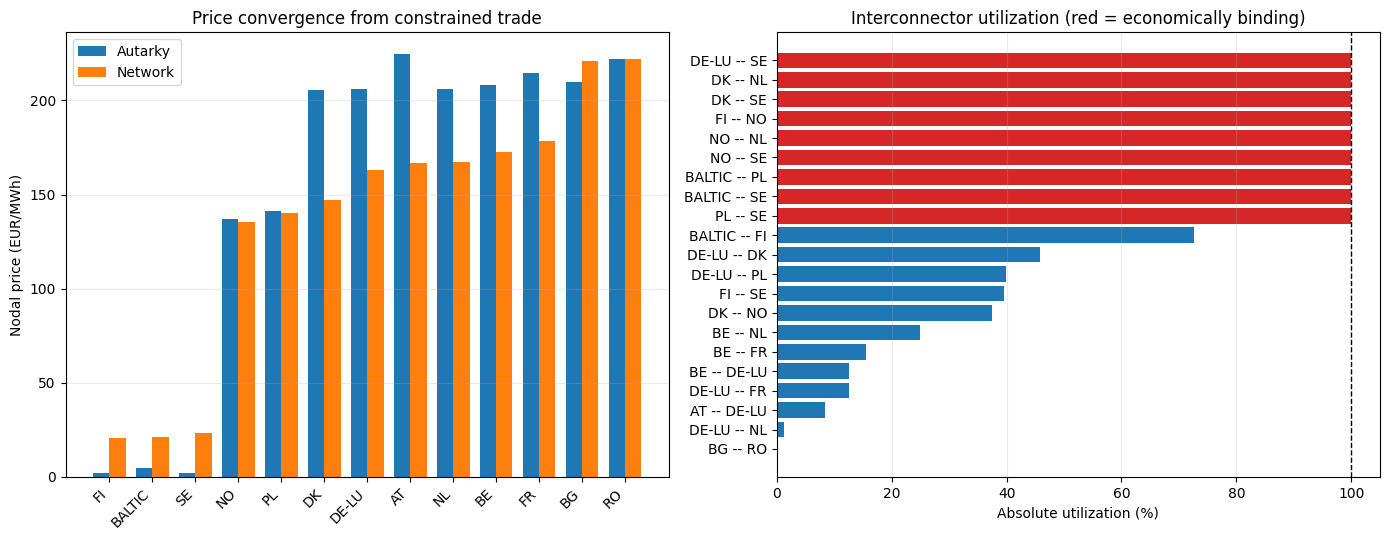

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

price_plot = node_comparison.sort_values("network_price")
x = np.arange(len(price_plot))
width = 0.38
axes[0].bar(x - width / 2, price_plot["autarky_price"], width, label="Autarky")
axes[0].bar(x + width / 2, price_plot["network_price"], width, label="Network")
axes[0].set_xticks(x, price_plot["market"], rotation=45, ha="right")
axes[0].set_ylabel("Nodal price (EUR/MWh)")
axes[0].set_title("Price convergence from constrained trade")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

utilization_plot = flow_display.sort_values("utilization_pct", ascending=True)
colors = np.where(utilization_plot["economically_binding"], "tab:red", "tab:blue")
axes[1].barh(
    utilization_plot["configured_link"],
    utilization_plot["utilization_pct"],
    color=colors,
)
axes[1].axvline(100, color="black", linewidth=1, linestyle="--")
axes[1].set_xlabel("Absolute utilization (%)")
axes[1].set_title("Interconnector utilization (red = economically binding)")
axes[1].grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

### Electrical loss and conductor loading

These plots use the optimized flows and the edge-specific electrical inputs. The left panel compares the exact quadratic `3 I²R` curve with each selected edge's PWL operating loss; the right panel ranks the actual modeled losses in the current network.

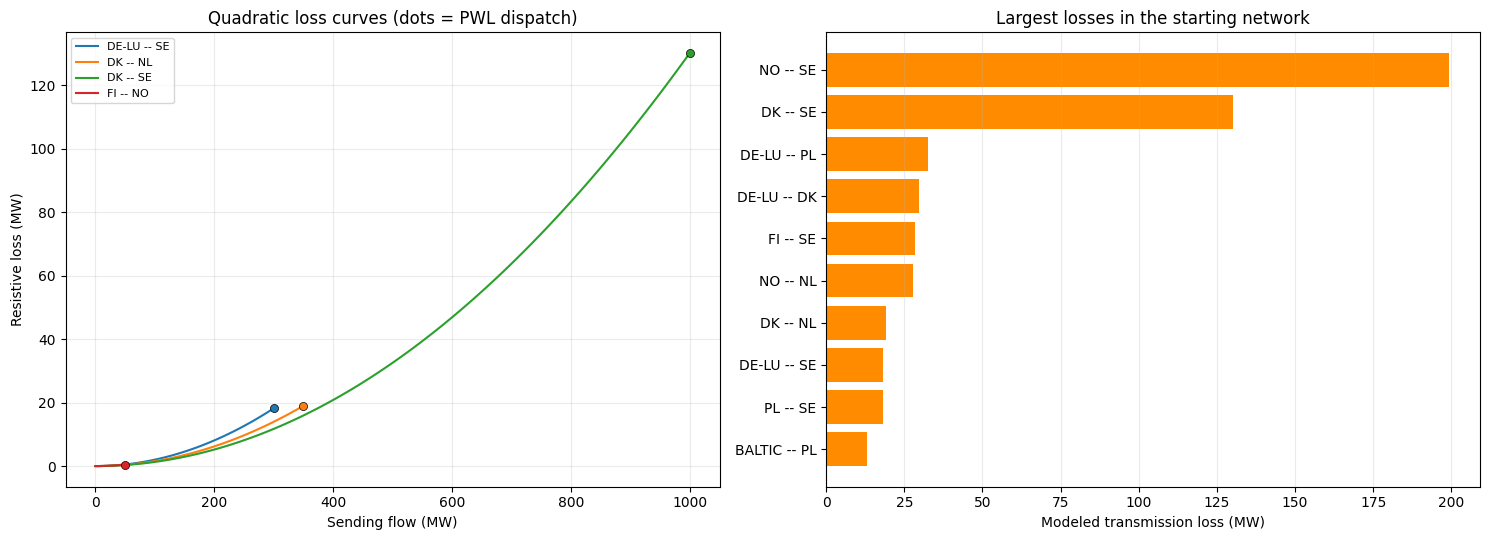

,configured_link,flow_mw,flow_limit_mw,utilization,current_a,loss_mw,utilization_pct
0,DE-LU -- SE,300.000,300.000,1.000,433.013,18.197,100.000
1,DK -- NL,350.000,350.000,1.000,505.181,18.994,100.000
2,DK -- SE,"1,000.000","1,000.000",1.000,"1,443.376",130.210,100.000
3,FI -- NO,50.000,50.000,1.000,72.169,0.492,100.000
4,NO -- NL,350.000,350.000,1.000,505.181,27.907,100.000
5,NO -- SE,"1,385.641","1,385.641",1.000,"2,000.000",199.206,100.000
6,BALTIC -- PL,250.000,250.000,1.000,360.844,13.009,100.000
7,BALTIC -- SE,350.000,350.000,1.000,505.181,11.585,100.000
8,PL -- SE,300.000,300.000,1.000,433.013,18.195,100.000
9,BALTIC -- FI,363.109,500.000,0.726,524.103,2.714,72.622


In [12]:
# Compare the physical quadratic loss curve with the PWL loss used by the optimizer.
flow_lookup = network["flows"].set_index("configured_link")
physics_links = flow_lookup.sort_values("utilization", ascending=False).head(4).index.tolist()
edge_lookup = {
    f"{row.from_market} -- {row.to_market}": row
    for row in INTERCONNECTORS.itertuples(index=False)
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for link in physics_links:
    flow_row = flow_lookup.loc[link]
    edge = edge_lookup[link]
    upper = float(flow_row["flow_limit_mw"])
    trial_flows = np.linspace(0.0, upper, 100)
    exact_losses = [
        resistive_loss_mw(q, flow_row["resistance_ohm"], edge.voltage_line_v, edge.power_factor)
        for q in trial_flows
    ]
    axes[0].plot(trial_flows, exact_losses, label=link)
    axes[0].scatter(
        [flow_row["flow_mw"]], [flow_row["loss_mw"]],
        s=34, edgecolor="black", linewidth=0.5, zorder=3,
    )
axes[0].set_xlabel("Sending flow (MW)")
axes[0].set_ylabel("Resistive loss (MW)")
axes[0].set_title("Quadratic loss curves (dots = PWL dispatch)")
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8)

loss_rank = network["flows"].nlargest(10, "loss_mw").sort_values("loss_mw")
axes[1].barh(loss_rank["configured_link"], loss_rank["loss_mw"], color="darkorange")
axes[1].set_xlabel("Modeled transmission loss (MW)")
axes[1].set_title("Largest losses in the starting network")
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

loading_view = network["flows"][[
    "configured_link", "flow_mw", "flow_limit_mw", "utilization", "current_a", "loss_mw"
]].copy()
loading_view["utilization_pct"] = 100.0 * loading_view["utilization"]
display(loading_view.sort_values("utilization_pct", ascending=False).head(10))

## 7. Numerical checks and interpretation

- `balance_residual_mw` should be essentially zero at every market.
- `loss_mw` is calculated from the piecewise-linear approximation to `3 I²R`; `received_mw` equals sent flow minus this loss.
- The MILP selects one direction per link. The nodal-price diagnostics come from a second continuous solve conditional on the chosen directions.
- `thermal_limit_mw` follows three-phase voltage and ampacity; `flow_limit_mw` is the minimum of the thermal rating and the applicable transfer-capacity cap.
- The summed market net exports should equal aggregate transmission losses.
- The illustrative defaults omit reactive power, voltage variation, temperature effects, multi-conductor bundle details, and route geometry.

In [13]:
diagnostics = pd.Series(
    {
        "max_abs_balance_residual_mw": network["nodes"]["balance_residual_mw"].abs().max(),
        "system_net_export_mw": network["nodes"]["net_export_mw"].sum(),
        "total_transmission_loss_mw": network["flows"]["loss_mw"].sum(),
        "interconnectors_at_limit": int(network["flows"]["at_limit"].sum()),
        "economically_binding_interconnectors": int(
            network["flows"]["economically_binding"].sum()
        ),
        "welfare_gain_eur_per_h": network["welfare"] - autarky["welfare"],
        "welfare_gain_for_15min_eur": 0.25 * (network["welfare"] - autarky["welfare"]),
    },
    name="value",
)
display(diagnostics.to_frame())

assert diagnostics["max_abs_balance_residual_mw"] <= 1e-5
assert np.isclose(
    diagnostics["system_net_export_mw"],
    diagnostics["total_transmission_loss_mw"],
    atol=1e-5,
)
assert network["welfare"] >= autarky["welfare"] - 1e-4
print("All numerical checks passed.")

,value
max_abs_balance_residual_mw,0.000
system_net_export_mw,562.942
total_transmission_loss_mw,562.942
interconnectors_at_limit,9.000
economically_binding_interconnectors,9.000
welfare_gain_eur_per_h,"463,412.042"
welfare_gain_for_15min_eur,"115,853.010"


All numerical checks passed.


## 8. Optional multi-period sensitivity

The same lossy market-clearing model can be run on several of the 96 delivery periods without extrapolating any curve. Set the switch below to `True` to compare representative overnight, morning, afternoon, and evening snapshots.

For a full-day welfare total, solve all 96 periods and multiply each EUR/hour objective by 0.25 hours before summing.

In [14]:
RUN_MULTI_PERIOD_SENSITIVITY = False
REPRESENTATIVE_PERIODS = [0, 28, 52, 76]


def run_period_sensitivity(markets, period_indices, interconnectors):
    rows = []
    for period_index in period_indices:
        one_period = prepare_period(markets, period_index)
        autarky_result = solve_market(
            one_period,
            AUTARKY_LINKS,
            model_name=f"autarky_period_{period_index}",
        )
        network_result = solve_market(
            one_period,
            interconnectors,
            model_name=f"network_period_{period_index}",
        )
        rows.append(
            {
                "period_index": period_index,
                "delivery_start": network_result["delivery_start"],
                "delivery_end": network_result["delivery_end"],
                "autarky_welfare_eur_per_h": autarky_result["welfare"],
                "network_welfare_eur_per_h": network_result["welfare"],
                "gain_for_15min_eur": 0.25 * (
                    network_result["welfare"] - autarky_result["welfare"]
                ),
                "economically_binding_links": int(
                    network_result["flows"]["economically_binding"].sum()
                ),
            }
        )
    return pd.DataFrame(rows)


if RUN_MULTI_PERIOD_SENSITIVITY:
    sensitivity_results = run_period_sensitivity(
        markets,
        REPRESENTATIVE_PERIODS,
        INTERCONNECTORS,
    )
    display(sensitivity_results)

## 9. Greedy transmission investment: new links and conductor upgrades

The starting network is treated as pre-existing; only selected investment actions count against the budget. Each iteration compares every affordable new-link build with a one-step conductor-area upgrade for each eligible existing link. An upgrade multiplies conductor area, ampacity, and the link's baseline transfer cap by `AREA_UPGRADE_MULTIPLIER`; resistance therefore falls by the reciprocal factor. New links use the existing distance-based construction cost (£1.6 million/km); conductor upgrades cost 40% of that rate (£0.64 million/km), scaled by the existing link length. This 40% is an illustrative midpoint scenario, not a project quote.

The greedy search selects the feasible action with the largest incremental welfare gain, then repeats until the budget, iteration cap, or gain threshold stops it. The exhaustive search can require many optimization solves, so it is opt-in below. All investment costs and budgets are reported in million GBP; welfare remains EUR. Investment costs and budgets are reported in million GBP; welfare remains EUR. The electrical and cost defaults are illustrative, not engineering recommendations.

Welfare objectives and gains are in EUR/hour; the investment history and summary also show the corresponding EUR per 15-minute interval (`0.25 × EUR/hour`), which matches the delivery period being analyzed.

In [15]:
from itertools import combinations


def make_candidate_edge(market_a, market_b, base_capacity_mw):
    """Construct a new-link candidate with the editable electrical defaults."""
    row = pd.DataFrame([{
        "from_market": market_a,
        "to_market": market_b,
        "capacity_mw": float(base_capacity_mw),
        "base_capacity_mw": float(base_capacity_mw),
    }])
    return add_physics_parameters(row).iloc[0].to_dict()


def upgrade_edge(network, edge_index):
    """Return a copy of the network with one edge advanced by one gauge step."""
    upgraded = network.copy(deep=True)
    row = upgraded.loc[edge_index].copy()
    if float(row["area_multiplier"]) >= AREA_UPGRADE_MULTIPLIER - 1e-9:
        raise ValueError("This edge has already received its one allowed gauge upgrade")
    row["area_multiplier"] = AREA_UPGRADE_MULTIPLIER
    row["capacity_mw"] = float(row["base_capacity_mw"]) * AREA_UPGRADE_MULTIPLIER
    upgraded.loc[edge_index] = row
    return upgraded


def greedy_investment_search(
    period_data,
    initial_interconnectors,
    budget_multiplier=BUDGET_MULTIPLIER,
    max_iterations=MAX_GREEDY_ITERATIONS,
    min_surplus_gain=MIN_SURPLUS_GAIN,
):
    """Greedily compare affordable new-link builds and single-step upgrades."""
    nodes = sorted(period_data)
    missing_coordinates = set(nodes) - set(MARKET_COORDINATES)
    if missing_coordinates:
        raise KeyError(f"Missing coordinates for markets: {sorted(missing_coordinates)}")
    all_pairs = list(combinations(nodes, 2))
    pair_costs = {pair: edge_creation_cost(*pair) for pair in all_pairs}
    budget = float(budget_multiplier * max(pair_costs.values()))
    current = initial_interconnectors.reset_index(drop=True).copy()
    initial = solve_market(period_data, current, model_name="investment_initial", diagnostics=False)
    initial_welfare = float(initial["welfare"])
    initial["model"].dispose()
    current_welfare = initial_welfare
    spent = 0.0
    history = []

    for iteration in range(1, max_iterations + 1):
        connected = {
            tuple(sorted((row.from_market, row.to_market)))
            for row in current.itertuples(index=False)
        }
        actions = []

        for pair in all_pairs:
            if pair in connected:
                continue
            cost = pair_costs[pair]
            if spent + cost > budget:
                continue
            new_edge = make_candidate_edge(pair[0], pair[1], CANDIDATE_EDGE_CAPACITY_MW)
            trial_network = pd.concat([current, pd.DataFrame([new_edge])], ignore_index=True)
            action_name = f"Build {pair[0]} -- {pair[1]}"
            actions.append((action_name, "build", pair, cost, trial_network))

        for edge_index, row in current.iterrows():
            if float(row["area_multiplier"]) >= AREA_UPGRADE_MULTIPLIER - 1e-9:
                continue
            cost = float(row["upgrade_cost_million_gbp"])
            if spent + cost > budget:
                continue
            pair = (row["from_market"], row["to_market"])
            actions.append((f"Upgrade {pair[0]} -- {pair[1]}", "upgrade", pair, cost,
                            upgrade_edge(current, edge_index)))

        if not actions:
            print("Investment search stopped: no affordable build or upgrade actions remain.")
            break

        best = None
        for action_name, action_type, pair, cost, trial_network in actions:
            trial = solve_market(
                period_data,
                trial_network,
                model_name=f"investment_{iteration}_{action_type}_{pair[0]}_{pair[1]}",
                diagnostics=False,
            )
            trial_welfare = float(trial["welfare"])
            trial["model"].dispose()
            gain = trial_welfare - current_welfare
            if best is None or gain > best["gain"]:
                best = {
                    "action": action_name,
                    "type": action_type,
                    "pair": pair,
                    "cost": cost,
                    "network": trial_network,
                    "welfare": trial_welfare,
                    "gain": gain,
                }

        if best["gain"] <= min_surplus_gain:
            print(
                f"Investment search stopped: best gain {best['gain']:,.4f} does not exceed "
                f"the {min_surplus_gain:,.4f} threshold."
            )
            break

        previous = current
        current = best["network"]
        spent += best["cost"]
        current_welfare = best["welfare"]
        history.append({
            "iteration": iteration,
            "action": best["action"],
            "action_type": best["type"],
            "edge": f"{best['pair'][0]} -- {best['pair'][1]}",
            "investment_cost_million_gbp": best["cost"],
            "welfare_gain_eur_per_h": best["gain"],
            "welfare_gain_eur_per_15min": 0.25 * best["gain"],
            "network_welfare_eur_per_h": current_welfare,
            "network_welfare_eur_per_15min": 0.25 * current_welfare,
            "investment_spent_million_gbp": spent,
            "budget_remaining_million_gbp": budget - spent,
        })
        print(
            f"Iteration {iteration}: {best['action']}, gain={best['gain']:,.2f} EUR/h, "
            f"cost=£{best['cost']:,.2f}m, remaining budget=£{budget-spent:,.2f}m"
        )
        if spent >= budget:
            print("Investment search stopped: budget reached.")
            break

    return {
        "interconnectors": current,
        "history": pd.DataFrame(history),
        "initial_welfare": initial_welfare,
        "final_welfare": current_welfare,
        "budget": budget,
        "spent": spent,
    }


RUN_GREEDY_SEARCH = True
if RUN_GREEDY_SEARCH:
    investment_result = greedy_investment_search(period_data, INTERCONNECTORS)
    investment_summary = pd.DataFrame([{
        "starting_edges": len(INTERCONNECTORS),
        "actions_selected": len(investment_result["history"]),
        "ending_edges": len(investment_result["interconnectors"]),
        "initial_welfare_eur_per_h": investment_result["initial_welfare"],
        "initial_welfare_eur_per_15min": 0.25 * investment_result["initial_welfare"],
        "final_welfare_eur_per_h": investment_result["final_welfare"],
        "final_welfare_eur_per_15min": 0.25 * investment_result["final_welfare"],
        "total_welfare_gain_eur_per_h": investment_result["final_welfare"] - investment_result["initial_welfare"],
        "total_welfare_gain_eur_per_15min": 0.25 * (investment_result["final_welfare"] - investment_result["initial_welfare"]),
        "budget_million_gbp": investment_result["budget"],
        "spent_million_gbp": investment_result["spent"],
        "remaining_budget_million_gbp": investment_result["budget"] - investment_result["spent"],
    }])
    display(investment_summary)
    display(investment_result["history"])
    display(investment_result["interconnectors"])
else:
    print("Set RUN_GREEDY_SEARCH = True to run the full build/upgrade search.")

Iteration 1: Upgrade DK -- SE, gain=80,176.50 EUR/h, cost=£334.22m, remaining budget=£34,335.78m
Iteration 2: Build DE-LU -- FI, gain=28,099.69 EUR/h, cost=£1,773.00m, remaining budget=£32,562.78m
Iteration 3: Build BALTIC -- DE-LU, gain=15,334.27 EUR/h, cost=£1,670.00m, remaining budget=£30,892.78m
Iteration 4: Build FR -- SE, gain=12,085.46 EUR/h, cost=£2,481.00m, remaining budget=£28,411.78m
Iteration 5: Upgrade DE-LU -- FI, gain=8,641.59 EUR/h, cost=£709.47m, remaining budget=£27,702.32m
Iteration 6: Build BE -- SE, gain=7,565.12 EUR/h, cost=£2,055.00m, remaining budget=£25,647.32m
Iteration 7: Build FI -- RO, gain=6,033.85 EUR/h, cost=£2,803.00m, remaining budget=£22,844.32m
Iteration 8: Build NL -- SE, gain=5,695.77 EUR/h, cost=£1,806.00m, remaining budget=£21,038.32m
Iteration 9: Upgrade FR -- SE, gain=4,465.72 EUR/h, cost=£992.63m, remaining budget=£20,045.69m
Iteration 10: Upgrade DE-LU -- SE, gain=3,823.70 EUR/h, cost=£518.96m, remaining budget=£19,526.73m
Iteration 11: Build

,starting_edges,actions_selected,ending_edges,initial_welfare_eur_per_h,initial_welfare_eur_per_15min,final_welfare_eur_per_h,final_welfare_eur_per_15min,total_welfare_gain_eur_per_h,total_welfare_gain_eur_per_15min,budget_million_gbp,spent_million_gbp,remaining_budget_million_gbp
0,21,23,32,"456,514,177.095","114,128,544.274","456,708,642.784","114,177,160.696","194,465.689","48,616.422","34,670.000","34,652.773",17.227


,iteration,action,action_type,edge,investment_cost_million_gbp,welfare_gain_eur_per_h,welfare_gain_eur_per_15min,network_welfare_eur_per_h,network_welfare_eur_per_15min,investment_spent_million_gbp,budget_remaining_million_gbp
0,1,Upgrade DK -- SE,upgrade,DK -- SE,334.218,"80,176.505","20,044.126","456,594,353.600","114,148,588.400",334.218,"34,335.782"
1,2,Build DE-LU -- FI,build,DE-LU -- FI,"1,773.000","28,099.688","7,024.922","456,622,453.288","114,155,613.322","2,107.218","32,562.782"
2,3,Build BALTIC -- DE-LU,build,BALTIC -- DE-LU,"1,670.000","15,334.272","3,833.568","456,637,787.560","114,159,446.890","3,777.218","30,892.782"
3,4,Build FR -- SE,build,FR -- SE,"2,481.000","12,085.461","3,021.365","456,649,873.021","114,162,468.255","6,258.218","28,411.782"
4,5,Upgrade DE-LU -- FI,upgrade,DE-LU -- FI,709.466,"8,641.585","2,160.396","456,658,514.607","114,164,628.652","6,967.683","27,702.317"
5,6,Build BE -- SE,build,BE -- SE,"2,055.000","7,565.118","1,891.280","456,666,079.725","114,166,519.931","9,022.683","25,647.317"
6,7,Build FI -- RO,build,FI -- RO,"2,803.000","6,033.847","1,508.462","456,672,113.572","114,168,028.393","11,825.683","22,844.317"
7,8,Build NL -- SE,build,NL -- SE,"1,806.000","5,695.773","1,423.943","456,677,809.345","114,169,452.336","13,631.683","21,038.317"
8,9,Upgrade FR -- SE,upgrade,FR -- SE,992.627,"4,465.715","1,116.429","456,682,275.060","114,170,568.765","14,624.310","20,045.690"
9,10,Upgrade DE-LU -- SE,upgrade,DE-LU -- SE,518.958,"3,823.696",955.924,"456,686,098.756","114,171,524.689","15,143.268","19,526.732"


,from_market,to_market,capacity_mw,base_capacity_mw,area_multiplier,length_km,resistivity_ohm_m,base_radius_m,voltage_line_v,base_max_current_a,power_factor,creation_cost,upgrade_cost_million_gbp
0,AT,DE-LU,"2,000.000","2,000.000",1.000,523.579,0.000,0.015,"400,000.000","2,000.000",1.000,837,335.090
1,BE,DE-LU,"1,000.000","1,000.000",1.000,651.338,0.000,0.015,"400,000.000","2,000.000",1.000,1042,416.856
2,BE,FR,"1,750.000","1,750.000",1.000,263.904,0.000,0.015,"400,000.000","2,000.000",1.000,422,168.898
3,BE,NL,"1,200.000","1,200.000",1.000,173.044,0.000,0.015,"400,000.000","2,000.000",1.000,276,110.748
4,DE-LU,FR,"2,000.000","2,000.000",1.000,878.748,0.000,0.015,"400,000.000","2,000.000",1.000,1405,562.399
5,DE-LU,NL,"2,500.000","2,500.000",1.000,577.352,0.000,0.015,"400,000.000","2,000.000",1.000,923,369.505
6,DE-LU,PL,"1,250.000","1,250.000",1.000,517.413,0.000,0.015,"400,000.000","2,000.000",1.000,827,331.144
7,DE-LU,DK,"1,250.000","1,250.000",1.000,355.158,0.000,0.015,"400,000.000","2,000.000",1.000,568,227.301
8,DE-LU,SE,600.000,300.000,2.000,810.871,0.000,0.015,"400,000.000","2,000.000",1.000,1297,518.958
9,DK,NL,350.000,350.000,1.000,621.863,0.000,0.015,"400,000.000","2,000.000",1.000,994,397.993


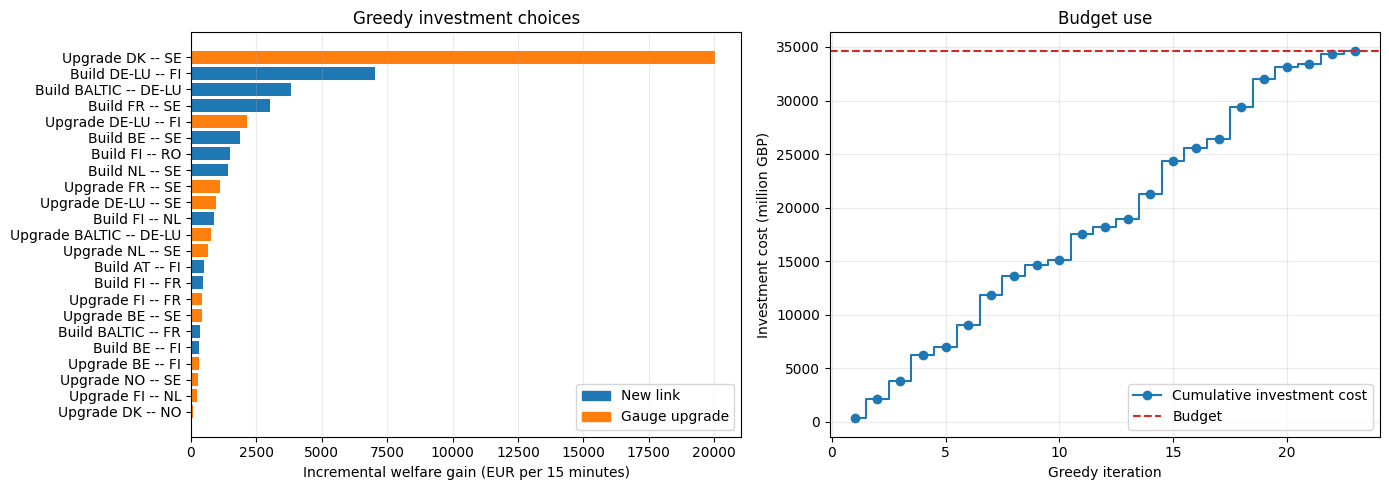

In [16]:
if RUN_GREEDY_SEARCH and not investment_result["history"].empty:
    action_plot = investment_result["history"].copy()
    action_plot["cumulative_spend"] = action_plot["investment_cost_million_gbp"].cumsum()
    colors = action_plot["action_type"].map({"build": "tab:blue", "upgrade": "tab:orange"})

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].barh(action_plot["action"], action_plot["welfare_gain_eur_per_15min"], color=colors)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("Incremental welfare gain (EUR per 15 minutes)")
    axes[0].set_title("Greedy investment choices")
    axes[0].grid(axis="x", alpha=0.25)
    axes[0].legend(handles=[
        plt.Rectangle((0, 0), 1, 1, color="tab:blue", label="New link"),
        plt.Rectangle((0, 0), 1, 1, color="tab:orange", label="Gauge upgrade"),
    ])

    axes[1].step(
        range(1, len(action_plot) + 1), action_plot["cumulative_spend"],
        where="mid", marker="o", label="Cumulative investment cost",
    )
    axes[1].axhline(investment_result["budget"], color="tab:red", linestyle="--", label="Budget")
    axes[1].set_xlabel("Greedy iteration")
    axes[1].set_ylabel("Investment cost (million GBP)")
    axes[1].set_title("Budget use")
    axes[1].grid(alpha=0.25)
    axes[1].legend()
    fig.tight_layout()
    plt.show()
elif RUN_GREEDY_SEARCH:
    print("No build or upgrade actions passed the gain threshold; no investment chart to display.")
else:
    print("Enable RUN_GREEDY_SEARCH to generate the build-versus-upgrade chart.")

## 10. Final network summary and market prices

The final table and plot include autarky, starting-network, and final-network nodal prices for each bidding area, including DK. With `RUN_GREEDY_SEARCH = False`, the final network is the configured starting network; with it enabled, final prices reflect the selected build/upgrade network.

The final summary reports welfare both in EUR/hour and in EUR for the selected 15-minute interval.

Final summary: Greedy investment network


,scenario,delivery_start,delivery_end,welfare_eur_per_h,welfare_eur_per_15min,total_transmission_loss_mw,number_of_links,upgraded_links,investment_spent_million_gbp,investment_budget_million_gbp
0,Greedy investment network,2026-09-07T22:00:00Z,2026-09-07T22:15:00Z,"456,708,642.784","114,177,160.696",226.583,32,12,"34,652.773","34,670.000"


Autarky, starting-network, and final-network nodal prices (EUR/MWh):


,market,autarky_price_eur_per_mwh,starting_network_price_eur_per_mwh,final_price_eur_per_mwh,final_supply_mw,final_demand_mw,final_net_export_mw,price_change_eur_per_mwh
0,AT,224.900,166.761,148.355,"3,137.800","3,295.400",-157.600,-18.406
1,BALTIC,5.010,21.060,130.844,"2,714.600","2,265.300",449.300,109.784
2,BE,208.000,172.532,144.040,"4,191.100","4,547.902",-356.802,-28.492
3,BG,210.000,221.110,138.502,"2,786.800","2,820.613",-33.813,-82.608
4,DE-LU,205.990,162.990,145.000,"31,052.772","32,434.137","-1,381.364",-17.990
5,DK,205.750,147.203,140.479,"3,189.100","3,759.713",-570.613,-6.724
6,FI,2.000,20.763,130.342,"8,991.107","7,628.872","1,362.235",109.578
7,FR,214.670,178.640,145.701,"17,363.643","18,073.135",-709.492,-32.939
8,NL,206.100,167.158,144.278,"8,463.000","9,193.223",-730.223,-22.880
9,NO,137.200,135.170,136.400,"12,121.677","12,471.200",-349.523,1.230


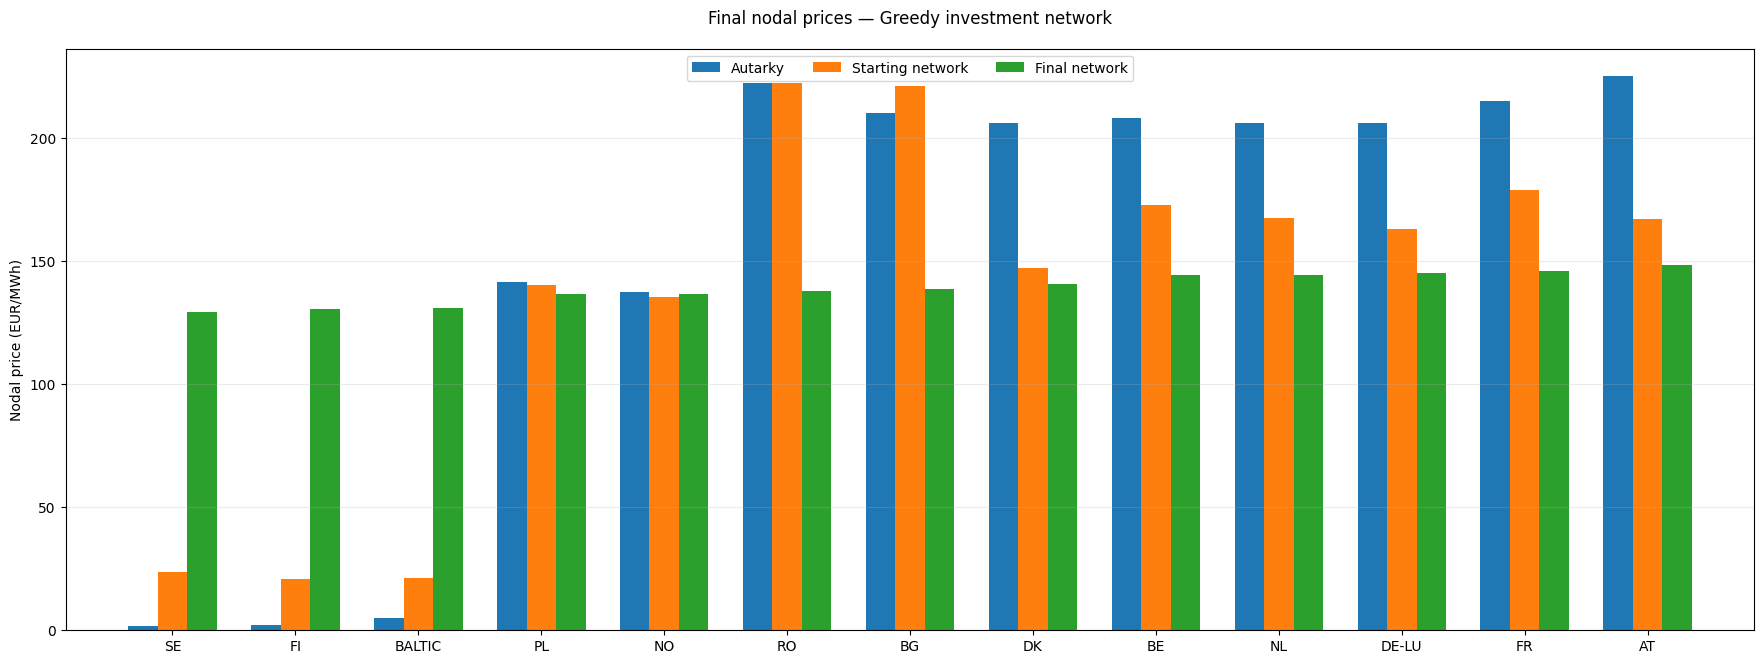

In [17]:
if RUN_GREEDY_SEARCH and "investment_result" in globals():
    final_interconnectors = investment_result["interconnectors"]
    final_scenario_name = "Greedy investment network"
else:
    final_interconnectors = INTERCONNECTORS
    final_scenario_name = "Starting network (no investments selected)"

final_solution = solve_market(
    period_data,
    final_interconnectors,
    model_name="final_network_summary",
    diagnostics=True,
)
final_market_summary = (
    autarky["nodes"][["market", "nodal_price_eur_per_mwh"]]
    .rename(columns={"nodal_price_eur_per_mwh": "autarky_price_eur_per_mwh"})
    .merge(
        network["nodes"][["market", "nodal_price_eur_per_mwh"]].rename(
            columns={"nodal_price_eur_per_mwh": "starting_network_price_eur_per_mwh"}
        ),
        on="market",
        how="inner",
        validate="one_to_one",
    )
    .merge(
        final_solution["nodes"][
            ["market", "nodal_price_eur_per_mwh", "supply_mw", "demand_mw", "net_export_mw"]
        ].rename(columns={
            "nodal_price_eur_per_mwh": "final_price_eur_per_mwh",
            "supply_mw": "final_supply_mw",
            "demand_mw": "final_demand_mw",
            "net_export_mw": "final_net_export_mw",
        }),
        on="market",
        how="inner",
        validate="one_to_one",
    )
)
final_market_summary["price_change_eur_per_mwh"] = (
    final_market_summary["final_price_eur_per_mwh"]
    - final_market_summary["starting_network_price_eur_per_mwh"]
)
final_market_summary = final_market_summary.sort_values("market").reset_index(drop=True)

final_summary = pd.DataFrame([{
    "scenario": final_scenario_name,
    "delivery_start": final_solution["delivery_start"],
    "delivery_end": final_solution["delivery_end"],
    "welfare_eur_per_h": final_solution["welfare"],
    "welfare_eur_per_15min": 0.25 * final_solution["welfare"],
    "total_transmission_loss_mw": float(final_solution["flows"]["loss_mw"].sum()),
    "number_of_links": len(final_interconnectors),
    "upgraded_links": int((final_interconnectors["area_multiplier"] > 1.0 + 1e-9).sum()),
    "investment_spent_million_gbp": (
        float(investment_result["spent"]) if RUN_GREEDY_SEARCH else 0.0
    ),
    "investment_budget_million_gbp": (
        float(investment_result["budget"]) if RUN_GREEDY_SEARCH else 0.0
    ),
}])
print(f"Final summary: {final_scenario_name}")
display(final_summary)
print("Autarky, starting-network, and final-network nodal prices (EUR/MWh):")
display(final_market_summary)

price_plot = final_market_summary.sort_values("final_price_eur_per_mwh")
x = np.arange(len(price_plot))
width = 0.24
fig, ax = plt.subplots(figsize=(18, 7))
ax.bar(x - width, price_plot["autarky_price_eur_per_mwh"], width, label="Autarky")
ax.bar(x, price_plot["starting_network_price_eur_per_mwh"], width, label="Starting network")
ax.bar(x + width, price_plot["final_price_eur_per_mwh"], width, label="Final network")
ax.set_xticks(x, price_plot["market"], rotation=0, ha="center", fontsize=10)
ax.set_ylabel("Nodal price (EUR/MWh)")
ax.set_title(f"Final nodal prices — {final_scenario_name}", pad=18)
ax.grid(axis="y", alpha=0.25)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
ax.margins(x=0.04)
fig.tight_layout(pad=2.0)
plt.show()

final_solution["model"].dispose()

## Suggested next extensions

1. Replace illustrative network, conductor, and cost inputs with sourced, date-consistent data.
2. Validate the loss and route-length assumptions against engineering data.
3. Run all 96 periods and summarize daily welfare and recurring investment candidates.
4. Put welfare and investment costs on a consistent financial basis for benefit-cost analysis.
5. If detailed grid behavior is required, replace the transport model with an AC or DC power-flow approximation.